# S5.2 · Record 11 — Cyclo[18]carbon

**SI:** page(s) 30; Table S4 record 11.  **Forms:** A, B.

**Constitution:** |V| = 18, |S| = 18, N_e = 108, Q = +0.

This notebook explicitly defines each construction word, executes its Replay, constructs the resulting electron allocation and constitution, checks both against the source, and draws the results. Nuclear indices are temporary addresses only. All H atoms and connections are shown by default.


In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
repo_root = next((p for p in (cwd, *cwd.parents)
                  if (p / 'examples' / 's5' / '_common.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Open within the CCS repository tree')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
from examples.s5._common import build_example, summarize_example, verify_example

example = build_example(11)
print(summarize_example(example))
replay_lengths = verify_example(example)
print('SI source record verified:', replay_lengths)


S5.2, Record 11: Cyclo[18]carbon
|V|=18, |S|=18, N_e=108, Q=+0; Forms: A, B
SI source record verified: {'A': 36, 'B': 36}


## 1. Explicit construction words

Each Form has a concrete Word([Nuc(...), Ele(), Con(...)]) declaration with every individual token written out. These words do not come from a runtime call to to_word().


In [2]:
from constructive_chemical_space import Word, Nuc, Ele, Con

# Literal SI S5 W(D): Nuc in displayed order, n_empty times Ele,
# then lexicographically ordered Con(i, j; ai, aj).
# Explicit input tokens, never auto-generated from an allocation at runtime.

# Form A
word_A = Word([
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Con(0, 1, 2, 2),
    Con(0, 17, 2, 2),
    Con(1, 2, 2, 2),
    Con(2, 3, 2, 2),
    Con(3, 4, 2, 2),
    Con(4, 5, 2, 2),
    Con(5, 6, 2, 2),
    Con(6, 7, 2, 2),
    Con(7, 8, 2, 2),
    Con(8, 9, 2, 2),
    Con(9, 10, 2, 2),
    Con(10, 11, 2, 2),
    Con(11, 12, 2, 2),
    Con(12, 13, 2, 2),
    Con(13, 14, 2, 2),
    Con(14, 15, 2, 2),
    Con(15, 16, 2, 2),
    Con(16, 17, 2, 2),
])

# Form B
word_B = Word([
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Nuc("C", 6),
    Con(0, 1, 3, 3),
    Con(0, 17, 1, 1),
    Con(1, 2, 1, 1),
    Con(2, 3, 3, 3),
    Con(3, 4, 1, 1),
    Con(4, 5, 3, 3),
    Con(5, 6, 1, 1),
    Con(6, 7, 3, 3),
    Con(7, 8, 1, 1),
    Con(8, 9, 3, 3),
    Con(9, 10, 1, 1),
    Con(10, 11, 3, 3),
    Con(11, 12, 1, 1),
    Con(12, 13, 3, 3),
    Con(13, 14, 1, 1),
    Con(14, 15, 3, 3),
    Con(15, 16, 1, 1),
    Con(16, 17, 3, 3),
])


## 2. Replay Word, construct D and M, verify the outputs

Each state_X is a real Replay state; allocation_X is the resulting intrinsic electron-allocation form, and constitution_X its CCS constitutional quotient. The source records are used only as verification references.


In [3]:
# These are real Replay results from the literal Words above,
# NOT the previously loaded reference input objects.

# Form A: Word -> Replay -> ElectronAllocation -> Constitution
state_A = word_A.replay_state()
allocation_A = state_A.form
constitution_A = allocation_A.to_constitution()
reference_A = example.forms["A"]
assert word_A.tokens == reference_A.to_word(order=example.order).tokens
assert allocation_A.to_word(order=state_A.address_table).tokens == word_A.tokens
assert tuple(v.identity for v in state_A.address_table) == tuple(v.identity for v in example.order)
assert allocation_A.num_electrons == reference_A.num_electrons
assert allocation_A.num_unassigned_electrons == reference_A.num_unassigned_electrons
assert constitution_A.num_electrons == example.constitution.num_electrons
assert constitution_A.total_charge == example.constitution.total_charge
assert len(constitution_A.connections) == len(example.constitution.connections)
if len(example.order) <= 15:
    assert allocation_A == reference_A
    assert constitution_A == example.constitution
print('Form A: explicit Word -> Replay -> D -> M verified; '
      'N_e =', allocation_A.num_electrons,
      ', tokens =', len(word_A.tokens))

# Form B: Word -> Replay -> ElectronAllocation -> Constitution
state_B = word_B.replay_state()
allocation_B = state_B.form
constitution_B = allocation_B.to_constitution()
reference_B = example.forms["B"]
assert word_B.tokens == reference_B.to_word(order=example.order).tokens
assert allocation_B.to_word(order=state_B.address_table).tokens == word_B.tokens
assert tuple(v.identity for v in state_B.address_table) == tuple(v.identity for v in example.order)
assert allocation_B.num_electrons == reference_B.num_electrons
assert allocation_B.num_unassigned_electrons == reference_B.num_unassigned_electrons
assert constitution_B.num_electrons == example.constitution.num_electrons
assert constitution_B.total_charge == example.constitution.total_charge
assert len(constitution_B.connections) == len(example.constitution.connections)
if len(example.order) <= 15:
    assert allocation_B == reference_B
    assert constitution_B == example.constitution
print('Form B: explicit Word -> Replay -> D -> M verified; '
      'N_e =', allocation_B.num_electrons,
      ', tokens =', len(word_B.tokens))


Form A: explicit Word -> Replay -> D -> M verified; N_e = 108 , tokens = 36
Form B: explicit Word -> Replay -> D -> M verified; N_e = 108 , tokens = 36


## 3. Visualize the generated CCS objects

The first image is constitution_A from word_A; the remaining images are the allocation_X objects from their explicit words. RDKit depiction is non-normative; every H and direct connection remains explicit.


Constitution generated from word_A


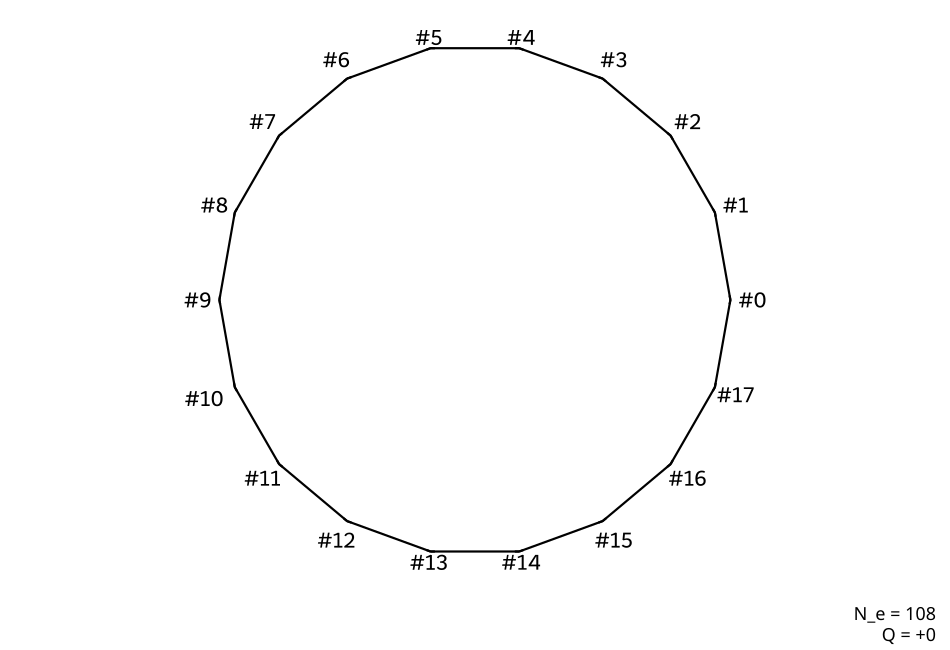

In [4]:
# Depict Constitution constructed by replaying the literal word_A.
draw_options = dict(show_hydrogens=True, show_indices=True,
                    show_total_charge=True,
                    width=1500 if len(example.order) > 60 else 950,
                    height=1000 if len(example.order) > 60 else 650)
print('Constitution generated from word_A')
constitution_A.show(order=state_A.address_table, **draw_options)


Electron allocation: Form A (generated by word_A)


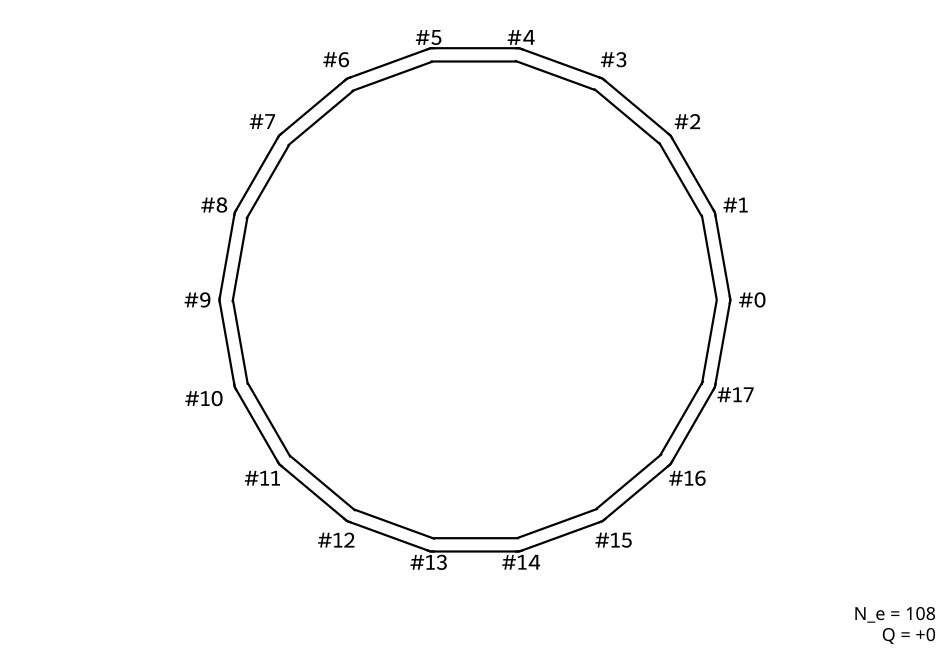

Electron allocation: Form B (generated by word_B)


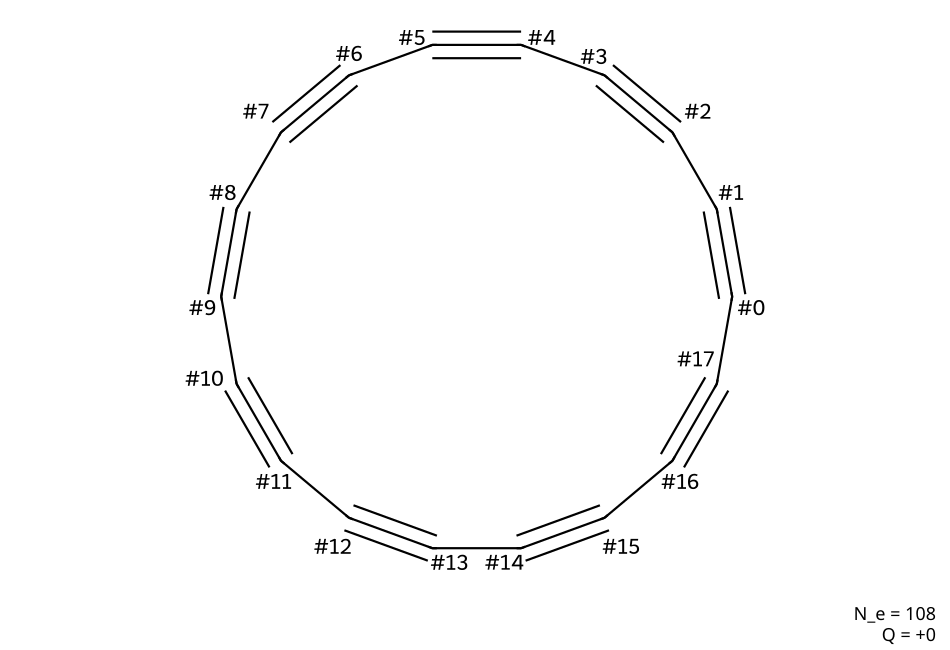

In [5]:
# Each image below visualizes a newly REPLAYED allocation object.
# Reference fixture forms are NOT used to generate these pictures.
print('Electron allocation: Form A (generated by word_A)')
allocation_A.show(order=state_A.address_table, **draw_options)
print('Electron allocation: Form B (generated by word_B)')
allocation_B.show(order=state_B.address_table, **draw_options)


## 4. Optional export of replayed results

EXPORT=False by default; change to True to save SVGs under the ignored examples/s5/outputs directory.


In [6]:
# Explicit opt-in export from the REPLAYED result, not input data.
# By default, only real notebook-kernel image outputs are retained.
EXPORT = False
if EXPORT:
    output_dir = repo_root / 'examples' / 's5' / 'outputs'
    output_dir.mkdir(parents=True, exist_ok=True)
    constitution_A.save(output_dir / 'S5_11_Cyclo18carbon_Constitution.svg',
                        order=state_A.address_table, **draw_options)
    allocation_A.save(output_dir / 'S5_11_Cyclo18carbon_Form_A.svg',
                           order=state_A.address_table, **draw_options)
    allocation_B.save(output_dir / 'S5_11_Cyclo18carbon_Form_B.svg',
                           order=state_B.address_table, **draw_options)
    print('Saved actual images under:', output_dir)
